In [1]:
import numpy as np 
import matplotlib
import matplotlib.pyplot as plt
from scipy import integrate

# Outbreaks 

## Why Use Models in Public Health?
### Public health scientists use epidemic models to forecast future outbreaks,
#### understand past ones, and plan effective interventions.

## From Theory to Simulation
### This lab turns textbook epidemic theory into hands-on computational simulations, 
### applying models to real-world outbreaks like Ebola and COVID-19.

## Real-World Relevance
### Models, even simple ones, have been used by WHO, CDC, and others 
### to guide public health decisions—sometimes in basic tools like Excel!

## What Makes This Lab Cool
### You will learn to code flexible and robust models (e.g., SIR models), 
### which simulate how diseases spread and how interventions
### like quarantine or vaccination change dynamics.

## What You Will Learn
### This lab teaches you to:

### Build epidemic models from scratch

### Analyze outbreak speed, strength, and size

### Understand in deterministic models how individuals move between states: 
### Susceptible → Infectious → Recovered/Removed

### Bonus: Stochasticity!

## SIR model

## Three Types of Individuals
### The population is divided into:

### S: Susceptible (can catch the disease)

### I: Infectious (currently spreading it)

### R: Recovered/Removed (no longer infectious)

### These add up to the total population: S + I + R = N

## The model uses rates to describe how individuals change states over time:

### dS/dt = –βSI → Susceptibles decrease as they get infected

### dI/dt = βSI – γI → Infectious individuals increase from new infections and decrease due to recovery

### dR/dt = γI → Recovered individuals increase as infectious people recover

### Where:
### β (beta) is the infection rate (depends on how often people interact and how likely infection is per contact)

### γ (gamma) is the recovery rate (how quickly infected people recover or are removed)

### These define the speed and spread of the outbreak

In [3]:
def sir_model(y, t, pars):
    S = y[0]
    I = y[1]
    dSdt = -pars['beta'] * S * I
    dIdt = pars['beta'] * S * I - pars['gamma'] * I
    dRdt = pars['gamma'] * I
    return [dSdt, dIdt, dRdt]


### How β Is Calculated
### If each susceptible person meets c people per time unit (contact rate), a fraction I/N of them are infectious,

### and p is the chance of infection per contact, then:
 
### β = cp and the infection rate becomes βSI



<div class="alert alert-block alert-warning">
<b>Challenge Problem: Challenge Problem: Outbreak Criteria</b>
    
***

Complete the simulation code below for the spread of an infectious disease beginning with 1 individual out of
10000 and estimate the value of R0. Do you expect the disease to spread or not? Then, change the value of p
to 0.01 – will the disease spread, why or why not?
    
Hint: Use an R0 of 2.0, but if you can guess - try and find R0 in terms of the parameters
   

</div>

R_0 = beta/gamma =  2.0


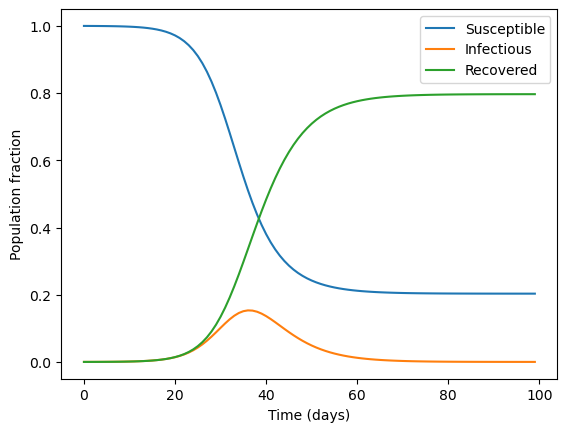

In [45]:

pars = {}
pars['c'] = 20               # Contacts per unit time (days)
pars['p'] = 0.025              # Probability of infectious contact
pars['beta'] = pars['c'] * pars['p']  # Transmission rate
pars['gamma'] = 1 / 4        # Recovery rate (1 / days)
pars['N'] = 10000              # Total population
pars['I0'] = 1                 # Initial number of infected individuals
pars['S0'] = pars['N'] - pars['I0']  # Initial number of susceptible individuals

print('R_0 = beta/gamma =  ' + str(pars['beta']/pars['gamma']))

y0 = np.array([pars['S0'], pars['I0'], 0]) / pars['N']


t = np.arange(100)


y = integrate.odeint(sir_model, y0, t, args=(pars,))


plt.plot(t, y[:, 0], label='Susceptible')
plt.plot(t, y[:, 1], label='Infectious')
plt.plot(t, y[:, 2], label='Recovered')
plt.xlabel('Time (days)')
plt.ylabel('Population fraction')
plt.legend()

plt.show()

## What happens after an outbreak begins?
## Public health scientists don’t just want to know if an outbreak will spread—they want to know:

### - How fast it will spread

### - How contagious it is

### - How many people will ultimately be infected

### Understanding these elements—speed, strength, and size—is essential to forecasting and managing infectious disease outbreaks.

## Speed of an outbreak:

### - Measured by the exponential growth rate, denoted as r

### - Early in an outbreak, the number of infectious individuals grows like $I(t)\sim e^{rt}$
 
### - Higher r means the number of cases is increasing rapidly over time

## Strength of an outbreak:

### - Measured by the basic reproduction number R₀

### - R₀ represents the average number of people one infectious individual infects in a completely susceptible population

### - For example, if R₀ = 2, each person infects 2 others on average

### - Outbreaks can only grow if R₀ > 1

## Size of an outbreak:

### - Refers to the total fraction of the population that gets infected

### - Denoted mathematicaly as --> Final size $= R(t\rightarrow\infty) = 1-S(t\rightarrow\infty)$

### - This is how many people will have been infected by the end of the outbreak

## Strength–Size Relationship:

### - Connects R₀ to the eventual fraction of people uninfected/infected: $S_\infty = e^{-R_0(1-S_\infty)}$ (read textbook for derivation)
### - $S_\infty$ denotes the people who never got infected
### - Shows that even if R₀ is only slightly above 1, a large outbreak is still possible
### - (small R₀ < 1 leads to a noticeably reduced $S_\infty$ )

## Strength–Speed Relationship:

### - Links R₀ and γ (recovery rate) to the outbreak’s initial speed $r = \gamma(R_0 -1)$


### At first glance, you might assume that a higher basic reproduction number (R₀) means an outbreak will always spread faster.

### But that's not always true — speed depends on more than just R₀.
### β (beta): transmission rate — how often infections occur per susceptible–infectious contact

### γ (gamma): recovery rate — how quickly infected individuals recover

### Together, these define both R₀ and the growth rate r of an outbreak

### $$R_0 = \beta/\gamma$$
### The speed of early outbreak growth however (denoted r) is denoted as 
###  $r = \gamma(R_0 -1)$ 
### Doing simple math can tell you how even if $R_0$ stays the same, r can increase (will reveal post challenge prob)


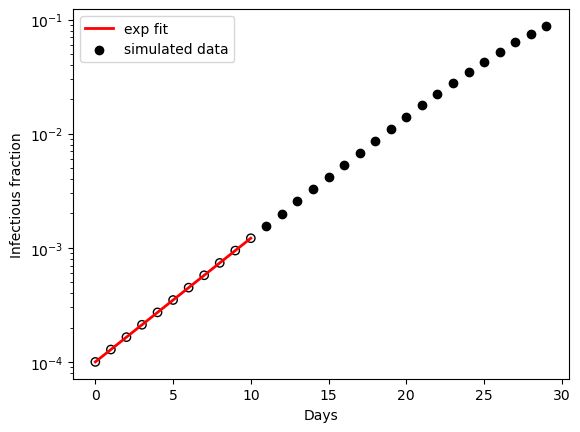

In [61]:
# Simulate outbreak over the first 11 days
t = np.arange(11)  # Time points from day 0 to 10
y = integrate.odeint(
    sir_model,                                # The SIR model function
    np.array([pars['S0'], pars['I0'], 0]) / pars['N'],  # Initial state (S, I, R) as population fractions
    t,
    args=(pars,)                              # Parameters passed into the model
)

# Estimate the exponential growth rate (r) from infectious case data
p = np.polyfit(t, np.log(y[:, 1]), 1)  # Fit a straight line to log(I(t)) vs time → slope ≈ growth rate r

# Plot the observed infectious cases (in log scale) and overlay the fitted exponential line
fig = plt.figure()
ax = fig.gca()
plt.scatter(t, y[:, 1], color='k', facecolor='none')  # Plot actual data points (infectious fraction)
ax.set_yscale('log')                                  # Use log scale for y-axis to visualize exponential growth
plt.plot(t, np.exp(p[0] * t + p[1]), color='r', linewidth=2, label = 'exp fit')  # Plot best-fit exponential curve

# Extend the simulation to 30 days and plot additional infectious data points
t = np.arange(30)
y = integrate.odeint(
    sir_model,
    np.array([pars['S0'], pars['I0'], 0]) / pars['N'],
    t,
    args=(pars,)
)
tmpi = np.argwhere(t > 10)  # Identify time points beyond day 10
plt.scatter(t[tmpi], y[tmpi, 1], color='k',label = 'simulated data')  # Plot future points as solid black markers
plt.xlabel('Days')
plt.ylabel('Infectious fraction')
plt.legend()

### The infectious fraction grows exponentially at the expected rate—slope = 0.2496/day, matching the predicted  r=0.25/day. 
### Your next task is to explore how varying β and γ affects the speed-strength relationship
### Strength ($R_0 = \beta/\gamma$) vs  Speed ($r = \gamma(R_0 -1)$)

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Strength-Speed Relationships </b>
    
***
Determine the strength and speed for the following sets of disease parameters
   

</div>

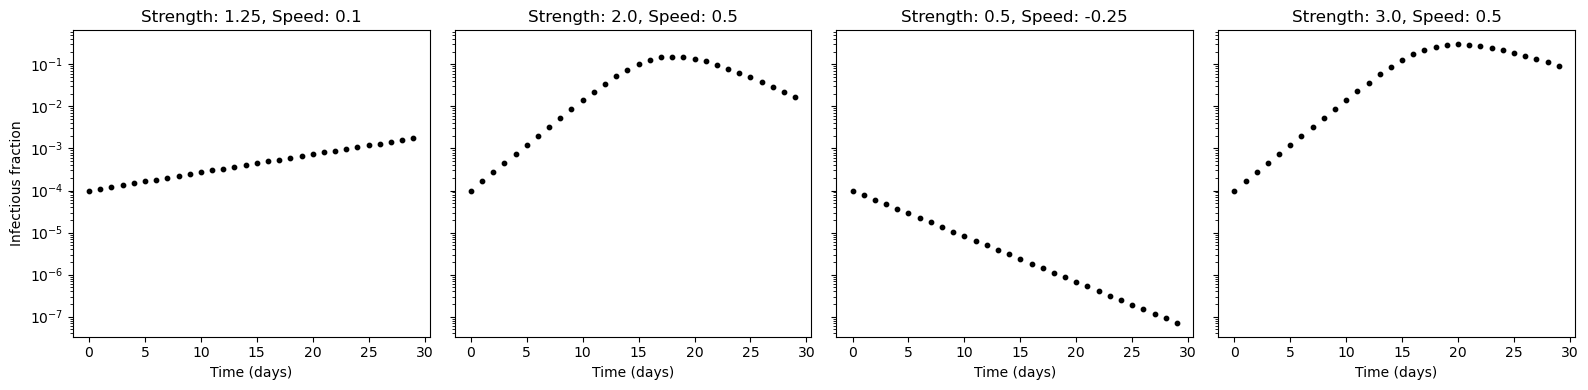

In [64]:
scenarios = [
    {'beta': 0.5, 'gamma': 0.4, 'label': 'Strength: 1.25, Speed: 0.1'},
    {'beta': 1.0, 'gamma': 0.5, 'label': 'Strength: 2.0, Speed: 0.5'},
    {'beta': 0.25, 'gamma': 0.5, 'label': 'Strength: 0.5, Speed: -0.25'},
    {'beta': 0.75, 'gamma': 0.25, 'label': 'Strength: 3.0, Speed: 0.5'}
]

# Time array (days)
t = np.arange(0, 30)

# Initial conditions (normalized in y0)
N = 10000
I0 = 1
S0 = N - I0
y0 = np.array([S0, I0, 0]) / N

# Create subplots
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for i, scenario in enumerate(scenarios):
    pars = {'beta': scenario['beta'], 'gamma': scenario['gamma']}
    y = integrate.odeint(sir_model, y0, t, args=(pars,))
    
    axes[i].scatter(t, y[:, 1], color='k', s=10)            # Infectious fraction
    axes[i].set_yscale('log')                               # Log scale for exponential behavior
    axes[i].set_title(scenario['label'])
    axes[i].set_xlabel('Time (days)')
    if i == 0:
        axes[i].set_ylabel('Infectious fraction')

plt.tight_layout()
plt.show()

### $r = \gamma(R_0 -1)  = \gamma(\beta/\gamma -1) = \beta - \gamma$

| β    | γ    | 𝑅₀ = β / γ | r = β − γ |
|------|------|------------|-----------|
| 0.5  | 0.4  | 1.25       | 0.1       |
| 1.0  | 0.5  | 2.0        | 0.5       |
| 0.25 | 0.5  | 0.5        | -0.25     |
| 0.75 | 0.25 | 3.0        | 0.5       |


## Final Size of an Epidemic:

### An outbreak does not infect everyone.

### The final size refers to the total fraction of people who were ever infected: $$R_\infty = 1-S_\infty$$

### Where $R_\infty$ are the people who recovered/removed
### $S_\infty$ are the people who never got infected 

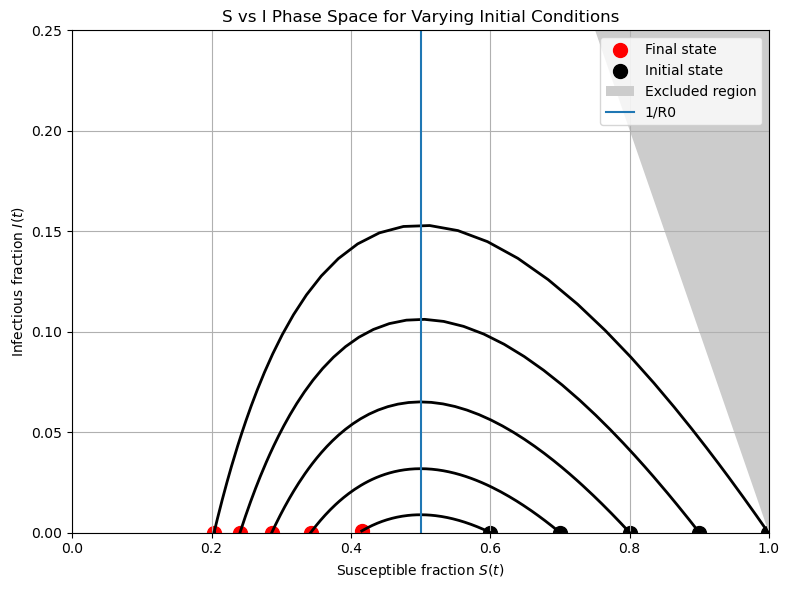

In [56]:
from matplotlib.patches import Polygon
pars = {}
pars['beta'] = 0.5                # Transmission rate
pars['gamma'] = 0.25              # Recovery rate
pars['N'] = 10000                 # Total population size

# Define multiple initial conditions
pars['S0_range'] = np.array([0.6, 0.7, 0.8, 0.9, 0.999])       # Different initial susceptible fractions
pars['I0_range'] = (1 / pars['N']) * np.ones(5)               # Small initial infected fraction (1 person)
pars['R0_range'] = 1 - pars['S0_range'] - pars['I0_range']     # Rest is assumed recovered (to keep total = 1)

# Set up the plot
fig = plt.figure(figsize=(8, 6))
ax = fig.gca()
plt.xlim([0, 1])
plt.ylim([0, 0.25])
plt.xlabel('Susceptible fraction $S(t)$')
plt.ylabel('Infectious fraction $I(t)$')
plt.title('S vs I Phase Space for Varying Initial Conditions')

# Simulate and plot each trajectory
for i in range(len(pars['S0_range'])):
    # Initial condition for each run
    y0 = [pars['S0_range'][i], pars['I0_range'][i], pars['R0_range'][i]]
    t = np.arange(200)

    # Solve SIR model
    y = integrate.odeint(sir_model, y0, t, args=(pars,))

    # Plot phase trajectory (S vs I)
    plt.plot(y[:, 0], y[:, 1], color='k', linewidth=2)

    # Mark final point (red) and initial point (black)
    plt.scatter(y[-1, 0], y[-1, 1], color='r', s=100, label='Final state' if i == 0 else "")
    plt.scatter(y[0, 0], y[0, 1], color='k', s=100, label='Initial state' if i == 0 else "")

# Add shaded "excluded" region where outbreak cannot take off
verts = [(1, 0), (1, 0.25), (0.75, 0.25)]  # Example triangle boundary
poly = Polygon(verts, facecolor=[0.8, 0.8, 0.8], label='Excluded region')
ax.add_patch(poly)

plt.axvline(1/(pars['beta']/pars['gamma']), label = '1/R0')
# Add legend
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

### - Each simulation starts at a black circle (initial state) and ends at a red circle (final state) in the S vs. I phase plot.
### - The simulations reveal a critical threshold at $1/R_0$ 
### - if the initial susceptible fraction is below this threshold, the outbreak won't spread (non existent trajectory)
### - This supports the idea of herd immunity: not everyone needs to be vaccinated, but more people must be immunized as $R_0$ increases.

### Strength ($R_0 = \beta/\gamma$) vs  Size ($R(t\rightarrow\infty) = 1-S(t\rightarrow\infty)$), where $S_\infty = e^{-R_0(1-S_\infty)}$)

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Strength-Size Relationships in Phase Space </b>
    
***
First, fix the value of the recovery rate to γ = 0.25, then modulate the transmission rate from β = 0.25 to
β = 2.5. Assume that initially, 80% of the population is susceptible and 20% is recovered. In this case, does
the disease always spread? Why or why not? In addition, find the outbreak size and show how it relates to
Ref f – the effective reproduction number given the initial susceptible population.
   

</div>

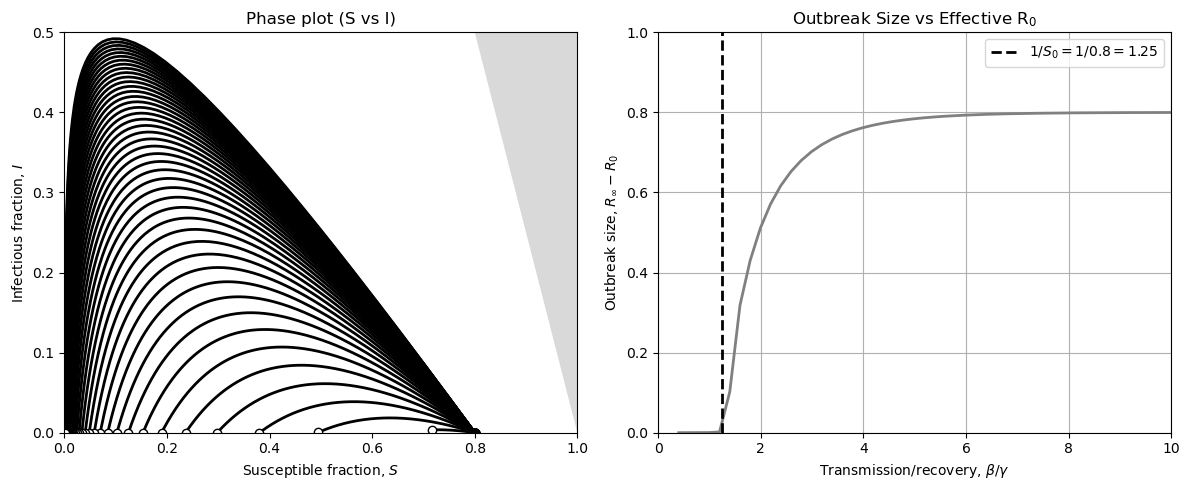

In [71]:

# Parameters
pars = {}
pars['gamma'] = 0.25           # Recovery rate
pars['N'] = 10000
pars['S0'] = 0.8               # 80% susceptible
pars['I0'] = 1 / pars['N']     # initial infection prop
pars['R0'] = 1 - pars['S0'] - pars['I0']

# Transmission rate range for simulations
beta_range = np.linspace(0.1, 2.5, 50)       # For left plot (S-I phase)
beta_fine = np.linspace(0.1, 10, 200)         # For right plot (outbreak size vs R0_eff)
t = np.arange(0, 200, 0.1)  # Time array
# Create figure with 2 subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
# -------- LEFT PLOT: S vs I Phase Trajectories --------
axs[0].set_xlim(0, 1)
axs[0].set_ylim(0, 0.5)
axs[0].set_xlabel('Susceptible fraction, $S$')
axs[0].set_ylabel('Infectious fraction, $I$')
axs[0].set_title('Phase plot (S vs I)')

for beta in beta_range:
    pars['beta'] = beta
    y = integrate.odeint(sir_model, [pars['S0'], pars['I0'], pars['R0']], t, args=(pars,))
    axs[0].plot(y[:, 0], y[:, 1], 'k', lw=2)
    axs[0].plot(y[0, 0], y[0, 1], 'ko', markersize=6)     # Initial point
    axs[0].plot(y[-1, 0], y[-1, 1], 'wo', markersize=6, markeredgecolor='k')  # Final point

# Add shaded triangle for excluded region
verts = [(1, 0), (pars['S0'], 0.5), (1, 0.5)]
poly = Polygon(verts, facecolor=[0.85, 0.85, 0.85])
axs[0].add_patch(poly)

# -------- RIGHT PLOT: Outbreak Size vs R_eff --------
R0_vals = beta_fine / pars['gamma']         # Reff = beta / gamma
R_end = []

for beta in beta_fine:
    pars['beta'] = beta
    y = integrate.odeint(sir_model, [pars['S0'], pars['I0'], pars['R0']], t, args=(pars,))
    R_end.append(y[-1, 2])  # Final recovered fraction

R_end = np.array(R_end)
outbreak_size = R_end - pars['R0']  # Outbreak size = R_inf - R_0

axs[1].plot(R0_vals, outbreak_size, color='gray', linewidth=2)
axs[1].axvline(x=1 / pars['S0'], color='k', linestyle='--', linewidth=2, label = '$1/S_0 = 1/0.8 = 1.25$')  # Threshold line
axs[1].set_xlim([0, 10])
axs[1].set_ylim([0, 1])
axs[1].set_xlabel(r'Transmission/recovery, $\beta/\gamma$')
axs[1].set_ylabel(r'Outbreak size, $R_\infty - R_0$')
axs[1].set_title('Outbreak Size vs Effective R$_0$')
axs[1].grid(True)

plt.legend()
plt.tight_layout()
plt.show()


### - The effective reproduction number is $R_{eff} = \beta S_0 / \gamma$ which in this case ranges from 0.8 to 8 depending on β
### - Even if $\beta > \gamma$ making $r = \beta - \gamma $ positive, an outbreak won't occur unless $R_{eff}>1$ 
### - or equivalently, $\beta/\gamma >1/S_0$
### - is threshold is visually confirmed in the plots: outbreaks only grow when $\beta/\gamma > 1/S_0$

## Endemicity
### The SIR model, with rapid loss of immunity can be written in terms of an SI model


### dS/dt = –βSI + γI  → Susceptibles decrease as they get infected but recovered people are immediately susceptible

### dI/dt = βSI – γI → Infectious individuals increase from new infections and decrease due to recovery

### This assumes no immunity and leads to possible endemic disease states:
### $S^* = 1/R_0$ and $I^* = (R_0-1)/R_0$

In [74]:
def si_model(y,t,pars):
    
    S = y[0]
    I = y[1]

    dSdt = -pars['beta']*S*I + pars['gamma']*I
    dIdt = pars['beta']*S*I - pars['gamma']*I
    dydt = [dSdt, dIdt]
    return dydt

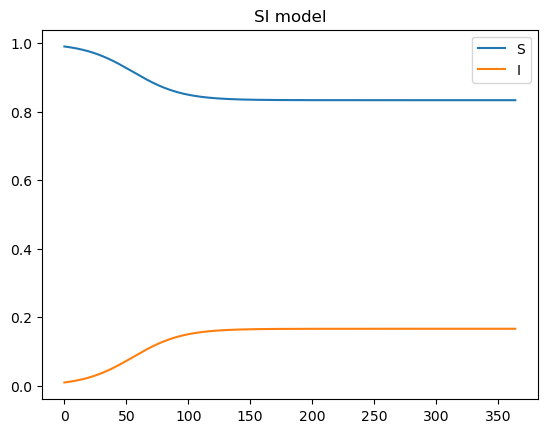

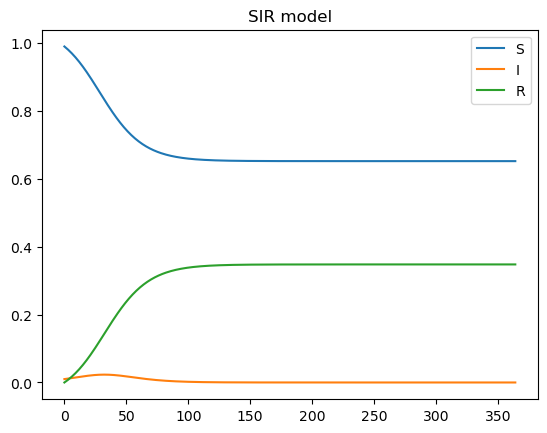

In [75]:
pars = {}
pars['gamma'] = 0.25           
pars['beta'] = 0.3
pars['N'] = 1           
pars['I0'] = 0.01     
pars['S0'] = pars['N'] - pars['I0']
pars['R0'] = 0 

t=np.arange(0,365)
y = integrate.odeint(si_model, [pars['S0'], pars['I0']], t, args=(pars,))

plt.plot(t,y[:,0], label = 'S')
plt.plot(t,y[:,1], label = 'I')
plt.legend()
plt.title('SI model')
plt.show()
y = integrate.odeint(sir_model, [pars['S0'], pars['I0'], pars['R0']], t, args=(pars,))
plt.plot(t,y[:,0], label = 'S')
plt.plot(t,y[:,1], label = 'I')
plt.plot(t,y[:,2], label = 'R')
plt.legend()
plt.title('SIR model')
plt.show()

## Stochastic frameworks

### The stochastic version of the SIR model simulates random individual-level events in an epidemic, using two core reactions:
### 1) Infection: S + I --> 2I with rate $r_1 = \frac{\beta IS}{N}$
### 2) Recovery: I --> R with rate $r_2 = \gamma I$

### with a total rate event (rate that one of the two things happens) is $r_{total} = r_1 + r_2$ 
### and the time to the next event is drawn from an exponential distribution using $1/r_{total}$
###  At each step, the type of event is chosen with probability $r_i/r_{total}$ and the population state is updated. 
### Simulation stops when there are no more infectious individuals
### This stochastic approach captures random variability in outbreak outcomes 
### and can be extended to more complex epidemic processes (e.g., SEIR, EVD with post-death transmission)
### The analysis focuses on non-extinct trajectories—those where the outbreak doesn't fade before the simulation ends.

# For the rest of this lab: 
## You will adapt the Gillespie algorithm to simulate a stochastic SIR epidemic 
## and compare its outcomes to the deterministic model to explore differences in outbreak dynamics

In [78]:
import numpy as np

def stochsim_SIR(y0, trange, pars):
    """
    Simulates a stochastic SIR model using the Gillespie algorithm.

    Parameters:
    y0     : list or array with initial values [S0, I0, R0]
    trange : list with time interval [t0, tf]
    pars   : dictionary with model parameters:
             'beta'  = transmission rate
             'gamma' = recovery rate
             'N'     = total population size

    Returns:
    t : list of time points at which events occurred
    y : array of [S, I, R] states at each corresponding time
    """

    # Initialize start and end time
    t0 = trange[0]
    tf = trange[1]
    
    # List to store time points
    t = [t0]
    
    # List to store population states: each entry is [S, I, R]
    y = [y0]

    # Current time and state
    tcur = t0
    ycur = list(y0)  # Make a mutable copy

    # Loop until simulation end time or epidemic dies out
    while tcur < tf:

        # If no more infectious individuals, epidemic is over
        if ycur[1] == 0:
            t.append(tf)
            y.append(ycur)
            break

        # STEP 1: Compute reaction rates 
        # Infection rate: β * S * I / N
        infrate = pars['beta'] * ycur[0] * ycur[1] / pars['N']
        
        # Recovery rate: γ * I
        recrate = pars['gamma'] * ycur[1]
        
        # Total rate of events
        totrate = infrate + recrate

        # STEP 2: Draw time to next event 
        # Time between events is exponentially distributed with mean 1/totrate
        dt = -np.log(np.random.uniform()) / totrate
        tcur += dt

        # STEP 3: Choose which event occurs
        if np.random.uniform() < (infrate / totrate):
            # Infection event: one susceptible becomes infected
            ycur[0] -= 1  # S → S - 1
            ycur[1] += 1  # I → I + 1
        else:
            # Recovery event: one infected recovers
            ycur[1] -= 1  # I → I - 1
            ycur[2] += 1  # R → R + 1

        # STEP 4: Store updated time and state 
        t.append(tcur)
        y.append(list(ycur))  # Save a copy of the new state

    # Convert result list to numpy array for easier analysis
    y = np.array(y)
    
    return t, y


In [79]:
def sir_model(y, t, pars):
    S, I, R = y
    dSdt = -pars['beta'] * S * I / pars['N']
    dIdt = pars['beta'] * S * I / pars['N'] - pars['gamma'] * I
    dRdt = pars['gamma'] * I
    return [dSdt, dIdt, dRdt]

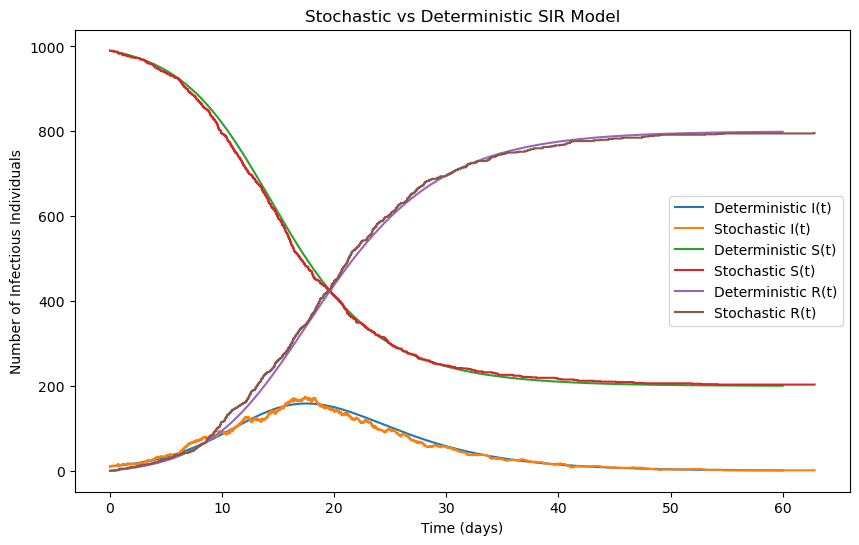

In [80]:
pars = {
    'c': 20,
    'p': 0.025,
    'gamma': 0.25,
    'tf': 60,
    'N': 1000,
    'I0': 10,
}
pars['beta'] = pars['c'] * pars['p']
pars['basR0'] = pars['beta'] / pars['gamma']
pars['S0'] = pars['N'] - pars['I0']
y0 = [pars['S0'], pars['I0'], 0]

# Run stochastic simulation
t_stoch, y_stoch = stochsim_SIR(y0, [0, pars['tf']], pars)

# Run deterministic simulation
t_det = np.linspace(0, pars['tf'], 500)
y_det = integrate.odeint(sir_model, y0, t_det, args=(pars,))

# Plot both
plt.figure(figsize=(10, 6))
plt.plot(t_det, y_det[:, 1], label='Deterministic I(t)')
plt.step(t_stoch, y_stoch[:, 1], label='Stochastic I(t)')
plt.plot(t_det, y_det[:, 0], label='Deterministic S(t)')
plt.step(t_stoch, y_stoch[:, 0], where='post', label='Stochastic S(t)')
plt.plot(t_det, y_det[:, 2], label='Deterministic R(t)')
plt.step(t_stoch, y_stoch[:, 2], where='post', label='Stochastic R(t)')
plt.xlabel('Time (days)')
plt.ylabel('Number of Infectious Individuals')
plt.title('Stochastic vs Deterministic SIR Model')
plt.legend()
plt.show()